# DuckDB Masterclass — Capítulo 12
## Armazenamento DuckDB: zonemaps e índices ART

**Edição didática para estudo autônomo e publicação**  
**Contexto:** Operations Analytics e telecomunicações | **Dados:** sintéticos  
**Roteiro:** hipótese → executar → validar → interpretar → desafio → autoavaliação.

> Execute as células **de cima para baixo** em um kernel limpo. Resultados reais só devem ser salvos depois da execução no seu ambiente. Não publique dados privados, credenciais ou caminhos absolutos.

## 12.1 — Objetivos e diagnóstico

- Entender como min/max pode reduzir leitura de segmentos.
- Comparar consulta por faixa e pontual.
- Criar índice ART e examinar planos sem prometer aceleração.
- Analisar filtros e condições para comparação justa.

**Pergunta de partida:** que risco operacional aparece quando utilizamos essa tecnologia de forma inadequada?

## 12.2 — Conceitos essenciais

Zonemaps aproveitam intervalos por blocos e a organização física dos dados. Índices ART são estruturas úteis para acesso pontual e imposição de certas restrições. Um `EXPLAIN` indica estratégia escolhida pelo otimizador, mas não prova velocidade ou uso efetivo de índice em toda execução.

### 🗺️ Modelo visual — Armazenamento DuckDB: zonemaps e índices ART

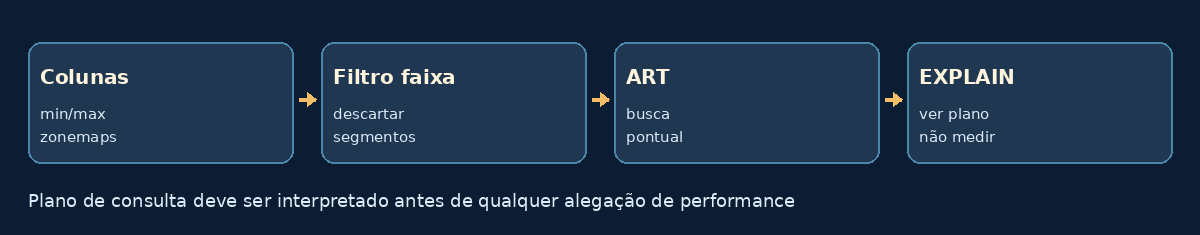

*Ilustração esquemática; não representa medição experimental.*

## 12.3 — Preparação e pré-requisitos

- Kernel recomendado: **Python (DuckDB Masterclass)**.
- Instale dependências ausentes no seu ambiente, fora do fluxo dos laboratórios.
- Cada arquivo produzido é sintético e deve ser salvo em pasta temporária ou `dados/` (ignorada pelo Git).
- Não execute instalação de extensões externas sem entender a necessidade, conectividade e eventuais custos.

## 12.4 — 🔬 Criar 100 mil medições sintéticas

**Hipótese / tarefa:** Usar chaves crescentes para facilitar avaliação de intervalos.

In [ ]:
import duckdb
from IPython.display import display
con = duckdb.connect(':memory:')
print('DuckDB:', duckdb.__version__)
con.execute('CREATE TABLE medicoes AS SELECT i id,i/1000 lote,i%200 latencia FROM range(100000) t(i)')
assert con.execute('SELECT COUNT(*) FROM medicoes').fetchone()[0]==100000
print('Medições geradas:',100000)

**Interpretação e limite:** O conjunto foi projetado e não reproduz carga de produção.

## 12.5 — 🔬 Filtrar faixa e validar contagem

**Hipótese / tarefa:** Comprovar que uma faixa contínua contém exatamente mil registros.

In [ ]:
q=con.execute('SELECT COUNT(*) FROM medicoes WHERE id BETWEEN 50000 AND 50999').fetchone()[0]
print('Linhas na faixa:',q)
assert q==1000

**Interpretação e limite:** A contagem não prova poda de segmentos.

## 12.6 — 🔬 Criar ART e analisar plano

**Hipótese / tarefa:** Comparar `EXPLAIN` para busca pontual e agregação.

In [ ]:
con.execute('CREATE INDEX idx_medicoes_id ON medicoes(id)')
for consulta in ['SELECT * FROM medicoes WHERE id=50123','SELECT AVG(latencia) FROM medicoes']:
 print('Consulta:',consulta)
 print(con.execute('EXPLAIN '+consulta).fetchone()[1])

**Interpretação e limite:** A escolha de plano depende de versão, cardinalidade e estatísticas.

## 12.7 — 🔬 Experimento sem afirmar ganho

**Hipótese / tarefa:** Comparar resultados de filtros com e sem condição.

In [ ]:
a=con.execute('SELECT COUNT(*) FROM medicoes WHERE id BETWEEN 50000 AND 50999').fetchone()[0]
b=con.execute('SELECT COUNT(*) FROM medicoes WHERE id>=50000 AND id<51000').fetchone()[0]
assert a==b==1000
print('Filtros logicamente equivalentes retornaram',a,'registros')

**Interpretação e limite:** Não confundir tempo de uma única medição com benchmark.

## 12.8 — 🎯 Desafio profissional

Em medições por intervalo de tempo, o que muda se registros estiverem ordenados ou aleatórios em disco?

**Critério de aceite:** apresentar a consulta ou procedimento, verificar uma hipótese e explicar pelo menos uma limitação. Resolva antes de consultar a referência abaixo.

### 🧠 Solução comentada / critérios de conferência

A ordenação pode aumentar a utilidade dos zonemaps, mas são necessárias evidências de profiling e comparação controlada.

## 12.9 — Autoavaliação

1. Explique o recurso sem reproduzir o código.
2. O que foi efetivamente demonstrado?
3. Que caso-limite poderia invalidar a interpretação?
4. Como validar a resposta com `assert`, SQL ou inspeção do plano?
5. Quando aplicaria isso em operações de telecomunicações?

**Gabarito orientador:** consulte a solução comentada do desafio e compare sua resposta com os resultados efetivamente observados; não conclua propriedades de performance ou produção sem evidência.

## 12.10 — Referências, reprodução e publicação

- [Indexing](https://duckdb.org/docs/stable/guides/performance/indexing)
- [EXPLAIN](https://duckdb.org/docs/stable/guides/meta/explain.html)
- [Performance Overview](https://duckdb.org/docs/stable/guides/performance/overview.html)

**Notas de engenharia:** Índice criado para fins didáticos; plano e custos dependem da versão instalada.

**Checklist editorial:** executar `Restart & Run All` quando aplicável; salvar saídas úteis; revisar integridade, privacidade, dependências e gráficos antes do `git add`.